# Medical Appointment No-Shows: What Makes Patients Miss Their Appointments?

**Dataset:** Medical Appointment No Shows (Kaggle, ~110k appointments, Brazil, Apr-Jun 2016)

**Research question:** Which factors are associated with a patient booking an appointment and then not showing up?

**Notebook structure**
1. Setup and loading
2. Data cleaning
3. Feature engineering
4. Exploratory data analysis
5. Patient history analysis
6. Statistical testing
7. Findings, limitations and recommendations

## 1. Setup and loading

In [11]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid')

In [12]:
# Change the path if you are not running on Colab
df = pd.read_csv('/content/KaggleV2-May-2016.csv')
rows_start = len(df)
print('Rows at start:', rows_start)
df.head()

Rows at start: 110527


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [13]:
df.info()
print()
print('Missing values per column:')
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  object 
 3   ScheduledDay    110527 non-null  object 
 4   AppointmentDay  110527 non-null  object 
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  object 
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 11.8+ MB

Missing values per column:
PatientId         0
AppointmentID     0
Gender            0
Sc

## 2. Data cleaning

Steps: remove duplicates, fix column names, build a clear target column, convert dates, and remove impossible values.

### 2.1 Duplicates and unused columns

Duplicates are checked **before** dropping the ID, otherwise different patients with identical attributes would be wrongly removed. `PatientId` is kept because it is used later for the patient-history analysis.

In [14]:
print('Duplicated AppointmentID:', df['AppointmentID'].duplicated().sum())
print('Fully duplicated rows   :', df.duplicated().sum())

Duplicated AppointmentID: 0
Fully duplicated rows   : 0


In [15]:
df = df.drop_duplicates(subset='AppointmentID')
df = df.drop(columns=['AppointmentID'])
df['PatientId'] = df['PatientId'].astype('int64')   # stored as float in the raw file

### 2.2 Column names and target variable

In the raw data `No-show = Yes` means the patient did **not** attend, which is confusing. We create a clear binary target: `no_show` (1 = missed, 0 = attended).

In [16]:
df = df.rename(columns={
    'Hipertension': 'Hypertension',
    'Handcap': 'Handicap',
    'No-show': 'No_show'
})
df.columns = df.columns.str.lower()

df['no_show'] = (df['no_show'] == 'Yes').astype(int)
print('Overall no-show rate: {:.1%}'.format(df['no_show'].mean()))

Overall no-show rate: 20.2%


### 2.3 Dates

In [17]:
raw_sched = df['scheduledday'].copy()
raw_appt = df['appointmentday'].copy()

df['scheduledday'] = pd.to_datetime(df['scheduledday'], format='ISO8601', errors='coerce', utc=True).dt.tz_localize(None)
df['appointmentday'] = pd.to_datetime(df['appointmentday'], format='ISO8601', errors='coerce', utc=True).dt.tz_localize(None)

bad = df['scheduledday'].isna() | df['appointmentday'].isna()
print('Rows with an unreadable date:', bad.sum())
if bad.sum() > 0:
    print(pd.DataFrame({'scheduledday_raw': raw_sched[bad], 'appointmentday_raw': raw_appt[bad]}))

df = df[~bad]
df[['scheduledday', 'appointmentday']].dtypes

Rows with an unreadable date: 0


,0
scheduledday,datetime64[ns]
appointmentday,datetime64[ns]


### 2.4 Impossible values

Negative ages and ages above 100 are treated as data-entry errors. Age 0 is kept (babies).

In [18]:
print(df['age'].describe())
print('Negative ages:', (df['age'] < 0).sum(), '| Ages > 100:', (df['age'] > 100).sum())
df = df[(df['age'] >= 0) & (df['age'] <= 100)]

count    110527.000000
mean         37.088874
std          23.110205
min          -1.000000
25%          18.000000
50%          37.000000
75%          55.000000
max         115.000000
Name: age, dtype: float64
Negative ages: 1 | Ages > 100: 7


Appointments scheduled **after** their own appointment date are logically impossible, so they are removed (checked after computing the waiting time below).

In [19]:
df['waiting_days'] = (df['appointmentday'].dt.normalize() - df['scheduledday'].dt.normalize()).dt.days
print('Appointments before booking date:', (df['waiting_days'] < 0).sum())
df = df[df['waiting_days'] >= 0]

print('Rows removed in total:', rows_start - len(df))
print('Rows kept            :', len(df))

Appointments before booking date: 5
Rows removed in total: 13
Rows kept            : 110514


## 3. Feature engineering

- `waiting_days` / `waiting_group`: days between booking and appointment
- `age_group`: life-stage categories
- `weekday`: day of the appointment
- `handicap_flag`: the raw `handicap` column has levels 0-4, we also keep a simple yes/no version

In [20]:
print(df['waiting_days'].value_counts().head(10))
print()
print(df['waiting_days'].quantile([0.5, 0.75, 0.9, 0.99]))

waiting_days
0     38560
2      6724
4      5290
1      5213
7      4906
6      4037
5      3277
14     2913
3      2735
8      2332
Name: count, dtype: int64

0.50     4.0
0.75    15.0
0.90    30.0
0.99    68.0
Name: waiting_days, dtype: float64


In [21]:
df['waiting_group'] = pd.cut(
    df['waiting_days'],
    bins=[-1, 0, 7, 30, df['waiting_days'].max()],
    labels=['Same day', '1-7 days', '8-30 days', '30+ days']
)

df['age_group'] = pd.cut(
    df['age'],
    bins=[-1, 12, 17, 35, 59, 100],
    labels=['Child (0-12)', 'Teen (13-17)', 'Young adult (18-35)', 'Adult (36-59)', 'Senior (60+)']
)

df['weekday'] = df['appointmentday'].dt.day_name()
df['handicap_flag'] = (df['handicap'] > 0).astype(int)

## 4. Exploratory data analysis

A reminder for reading the tables below: a rate is only meaningful together with its `count`, so counts are shown wherever groups can be small.

### 4.1 Waiting time

In [22]:
print(df.groupby('waiting_group', observed=True)['no_show'].agg(['mean', 'count']))

                   mean  count
waiting_group                 
Same day       0.046473  38560
1-7 days       0.241439  32182
8-30 days      0.317231  29395
30+ days       0.329960  10377


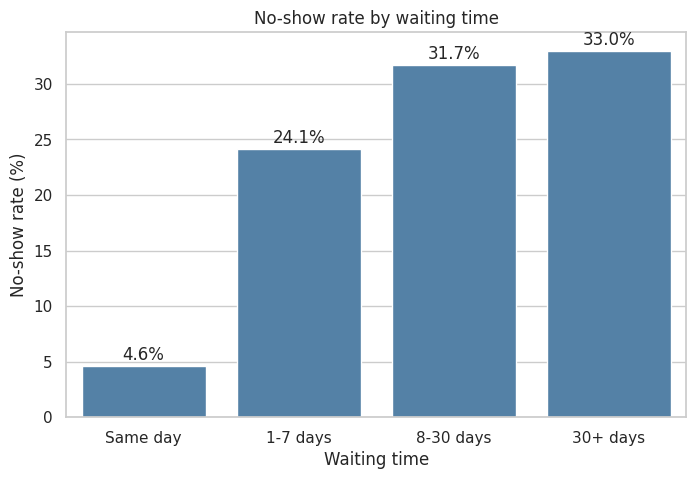

In [23]:
rates = df.groupby('waiting_group', observed=True)['no_show'].mean() * 100

plt.figure(figsize=(8, 5))
sns.barplot(x=rates.index, y=rates.values, color='steelblue')
plt.title('No-show rate by waiting time')
plt.ylabel('No-show rate (%)')
plt.xlabel('Waiting time')
for i, v in enumerate(rates.values):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center')
plt.show()

**Observation:** _(write what you see: how does the rate change from same-day to 30+ days?)_

### 4.2 Age

In [24]:
print(df.groupby('age_group', observed=True)['no_show'].agg(['mean', 'count']))

                         mean  count
age_group                           
Child (0-12)         0.204706  21035
Teen (13-17)         0.266435   6343
Young adult (18-35)  0.238116  25622
Adult (36-59)        0.191917  36349
Senior (60+)         0.152988  21165


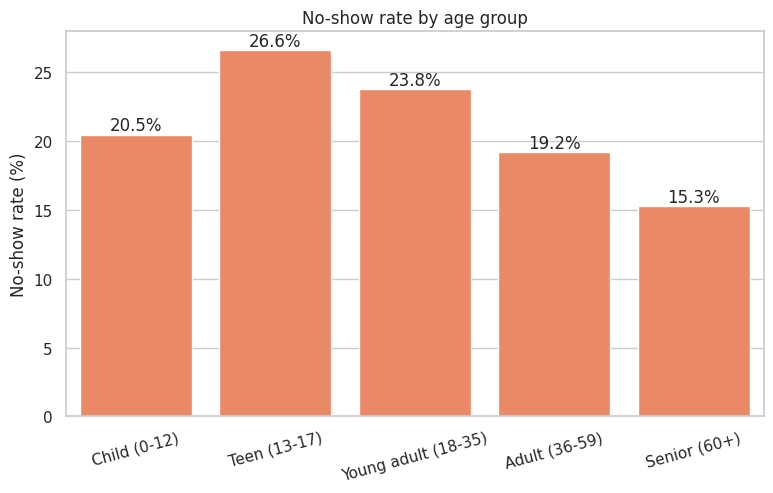

In [25]:
rates = df.groupby('age_group', observed=True)['no_show'].mean() * 100

plt.figure(figsize=(9, 5))
sns.barplot(x=rates.index, y=rates.values, color='coral')
plt.title('No-show rate by age group')
plt.ylabel('No-show rate (%)')
plt.xlabel('')
plt.xticks(rotation=15)
for i, v in enumerate(rates.values):
    plt.text(i, v + 0.3, f'{v:.1f}%', ha='center')
plt.show()

**Observation:** _(which group misses the most? which the least?)_

### 4.3 Weekday

In [26]:
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
print(df.groupby('weekday')['no_show'].agg(['mean', 'count']).reindex(order))

               mean    count
weekday                     
Monday     0.206420  22711.0
Tuesday    0.200882  25637.0
Wednesday  0.196861  25866.0
Thursday   0.193412  17243.0
Friday     0.212273  19018.0
Saturday   0.230769     39.0
Sunday          NaN      NaN


Saturday has very few appointments, so no strong conclusion should be drawn from it.

### 4.4 Gender

In [27]:
print(df.groupby('gender')['no_show'].agg(['mean', 'count']))

            mean  count
gender                 
F       0.203093  71829
M       0.199638  38685


**Observation:** _(is there a meaningful difference between F and M?)_

### 4.5 SMS reminders

At first glance SMS may look harmful (higher no-show among patients who received one). The next table tests whether this is a confounding effect of waiting time: SMS is mostly sent for appointments booked far in advance.

In [28]:
print(df.groupby('sms_received')['no_show'].agg(['mean', 'count']))

                  mean  count
sms_received                 
0             0.166953  75033
1             0.275753  35481


In [29]:
sms_by_wait = (df.groupby(['waiting_group', 'sms_received'], observed=True)['no_show']
                 .mean().unstack().rename(columns={0: 'No SMS', 1: 'SMS'}))
print((sms_by_wait * 100).round(1))
print()
print('SMS share per waiting group:')
print(df.groupby('waiting_group', observed=True)['sms_received'].mean().round(3))

sms_received   No SMS   SMS
waiting_group              
Same day          4.6   NaN
1-7 days         24.4  23.8
8-30 days        35.6  29.1
30+ days         37.5  30.2

SMS share per waiting group:
waiting_group
Same day     0.000
1-7 days     0.359
8-30 days    0.596
30+ days     0.618
Name: sms_received, dtype: float64


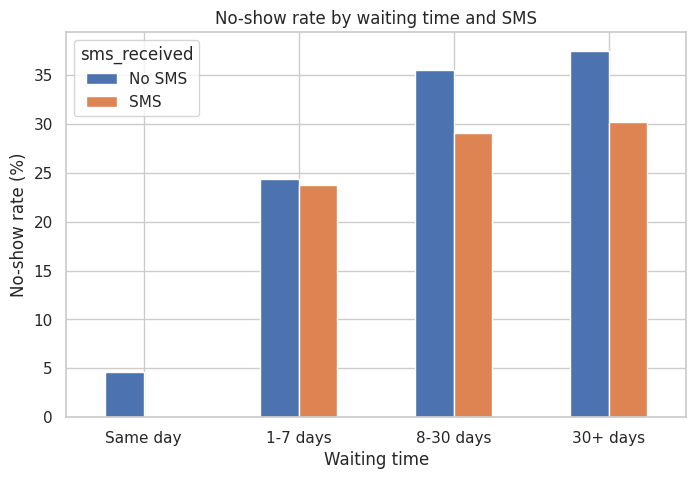

In [30]:
(sms_by_wait * 100).plot(kind='bar', figsize=(8, 5))
plt.title('No-show rate by waiting time and SMS')
plt.ylabel('No-show rate (%)')
plt.xlabel('Waiting time')
plt.xticks(rotation=0)
plt.show()

**Observation:** _(compare SMS vs No SMS inside each waiting group. Does the gap shrink, disappear or reverse?)_

### 4.6 Neighbourhoods

Only neighbourhoods with at least 500 appointments are shown, because tiny groups produce extreme and misleading rates.

In [31]:
hood = df.groupby('neighbourhood')['no_show'].agg(['mean', 'count'])
hood = hood[hood['count'] >= 500].sort_values('mean', ascending=False)

print(hood.head(10))
print()
print(hood.tail(5))

                       mean  count
neighbourhood                     
SANTOS DUMONT      0.289185   1276
SANTA CLARA        0.264822    506
ITARARÉ            0.262664   3514
JESUS DE NAZARETH  0.243954   2853
ILHA DO PRÍNCIPE   0.234775   2266
CARATOÍRA          0.230409   2565
ANDORINHAS         0.229407   2258
PRAIA DO SUÁ       0.228261   1288
GURIGICA           0.225966   2018
BENTO FERREIRA     0.224942    858

                     mean  count
neighbourhood                   
VILA RUBIM       0.165687    851
DO QUADRO        0.164900    849
JARDIM DA PENHA  0.162755   3877
SANTA MARTHA     0.158416   3131
DO CABRAL        0.157143    560


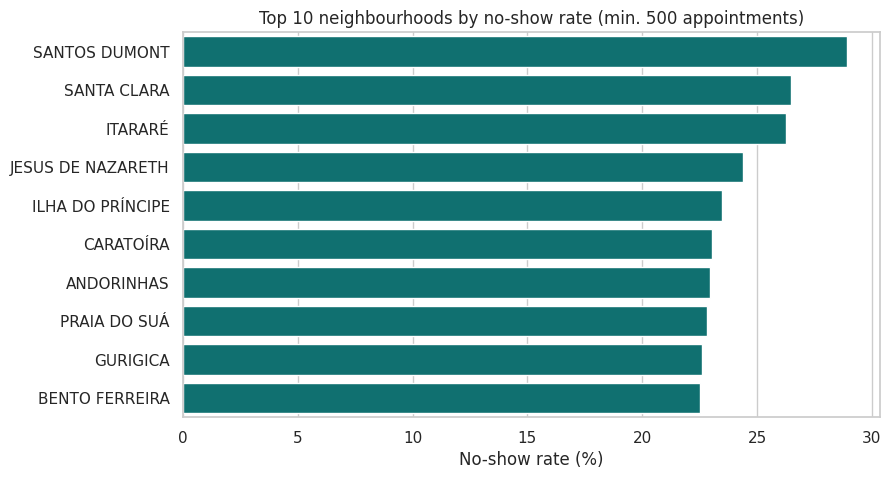

In [32]:
top = hood.head(10)['mean'] * 100

plt.figure(figsize=(9, 5))
sns.barplot(x=top.values, y=top.index, color='teal')
plt.title('Top 10 neighbourhoods by no-show rate (min. 500 appointments)')
plt.xlabel('No-show rate (%)')
plt.ylabel('')
plt.show()

### 4.7 Chronic conditions, scholarship and handicap

In [33]:
for col in ['hypertension', 'diabetes', 'alcoholism', 'scholarship', 'handicap_flag']:
    print(df.groupby(col)['no_show'].agg(['mean', 'count']), '\n')

                  mean  count
hypertension                 
0             0.208975  88714
1             0.173028  21800 

              mean   count
diabetes                  
0         0.203576  102571
1         0.180033    7943 

                mean   count
alcoholism                  
0           0.201896  107154
1           0.201488    3360 

                 mean  count
scholarship                 
0            0.198017  99653
1            0.237363  10861 

                   mean   count
handicap_flag                  
0              0.202338  108279
1              0.179866    2235 



Chronic patients are usually older, and older patients attend more. To check whether the condition itself matters, we compare inside each age group:

In [34]:
print(df.groupby(['age_group', 'hypertension'], observed=True)['no_show'].mean().unstack().round(3))
print()
print(df.groupby(['age_group', 'diabetes'], observed=True)['no_show'].mean().unstack().round(3))

hypertension             0      1
age_group                        
Child (0-12)         0.205  0.333
Teen (13-17)         0.266  0.346
Young adult (18-35)  0.239  0.211
Adult (36-59)        0.195  0.184
Senior (60+)         0.143  0.161

diabetes                 0      1
age_group                        
Child (0-12)         0.205  0.263
Teen (13-17)         0.266  0.344
Young adult (18-35)  0.238  0.274
Adult (36-59)        0.192  0.190
Senior (60+)         0.149  0.167


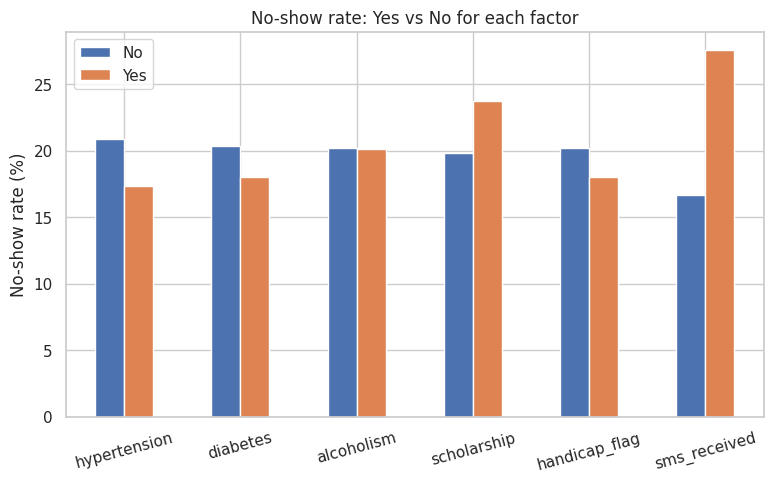

In [35]:
cols = ['hypertension', 'diabetes', 'alcoholism', 'scholarship', 'handicap_flag', 'sms_received']
rates = {c: df.groupby(c)['no_show'].mean() * 100 for c in cols}
plot_df = pd.DataFrame(rates).T.rename(columns={0: 'No', 1: 'Yes'})

plot_df.plot(kind='bar', figsize=(9, 5))
plt.title('No-show rate: Yes vs No for each factor')
plt.ylabel('No-show rate (%)')
plt.xticks(rotation=15)
plt.show()

### 4.8 Correlations

Correlations with a binary target are expected to be weak. Missing an appointment is a complex behaviour that no single variable explains.

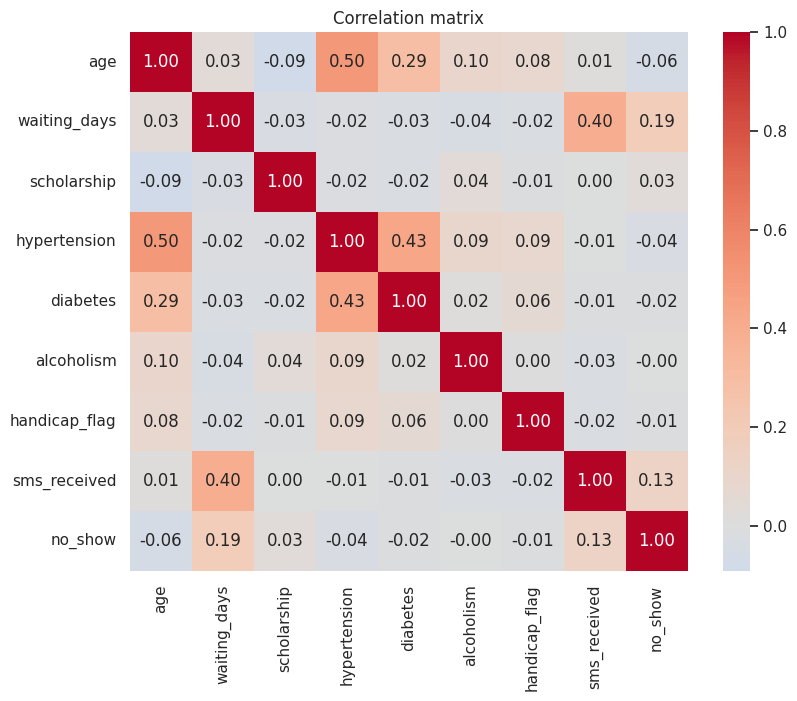

In [36]:
num_cols = ['age', 'waiting_days', 'scholarship', 'hypertension',
            'diabetes', 'alcoholism', 'handicap_flag', 'sms_received', 'no_show']

plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix')
plt.show()

## 5. Patient history analysis

Does a patient who missed before tend to miss again? For each appointment we count only the patient's **earlier** appointments, so the current outcome never leaks into its own feature.

In [37]:
df = df.sort_values(['patientid', 'appointmentday', 'scheduledday']).reset_index(drop=True)

df['prev_appointments'] = df.groupby('patientid').cumcount()
df['prev_noshows'] = df.groupby('patientid')['no_show'].cumsum() - df['no_show']
df['prev_noshow_rate'] = df['prev_noshows'] / df['prev_appointments'].replace(0, np.nan)

print('Appointments with a previous history:', (df['prev_appointments'] > 0).sum())

Appointments with a previous history: 48220


In [38]:
hist = df[df['prev_appointments'] > 0].copy()
hist['had_prev_noshow'] = (hist['prev_noshows'] > 0).map({True: 'Missed before', False: 'Never missed'})

print(hist.groupby('had_prev_noshow')['no_show'].agg(['mean', 'count']))

                     mean  count
had_prev_noshow                 
Missed before    0.291380  15962
Never missed     0.170469  32258


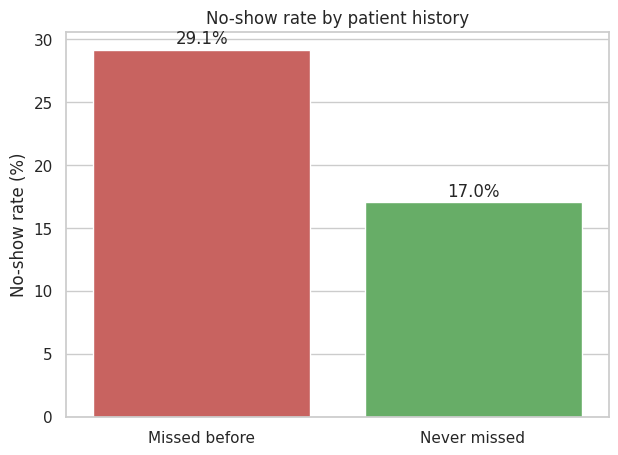

In [39]:
rates = hist.groupby('had_prev_noshow')['no_show'].mean() * 100

plt.figure(figsize=(7, 5))
sns.barplot(x=rates.index, y=rates.values, hue=rates.index,
            palette=['#d9534f', '#5cb85c'], legend=False)
plt.title('No-show rate by patient history')
plt.ylabel('No-show rate (%)')
plt.xlabel('')
for i, v in enumerate(rates.values):
    plt.text(i, v + 0.5, f'{v:.1f}%', ha='center')
plt.show()

**Observation:** _(how large is the gap between the two groups?)_

## 6. Statistical testing

With ~110k rows almost any difference is "statistically significant", so we report the **size of the difference** (percentage points) next to the Chi-square p-value.

In [40]:
def test_factor(data, col, label=None):
    ct = pd.crosstab(data[col], data['no_show'])
    chi2, p, dof, _ = chi2_contingency(ct)
    rates = data.groupby(col)['no_show'].mean() * 100
    return {
        'factor': label or col,
        'rate_lowest_group_%': round(rates.min(), 1),
        'rate_highest_group_%': round(rates.max(), 1),
        'gap_pp': round(rates.max() - rates.min(), 1),
        'p_value': p,
    }

results = [
    test_factor(df, 'sms_received', 'SMS received'),
    test_factor(df, 'scholarship', 'Scholarship'),
    test_factor(df, 'hypertension', 'Hypertension'),
    test_factor(df, 'diabetes', 'Diabetes'),
    test_factor(df, 'alcoholism', 'Alcoholism'),
    test_factor(df, 'handicap_flag', 'Handicap'),
    test_factor(df, 'gender', 'Gender'),
    test_factor(df, 'waiting_group', 'Waiting time group'),
    test_factor(df, 'age_group', 'Age group'),
    test_factor(hist, 'had_prev_noshow', 'Missed an earlier appointment'),
]

stats_table = pd.DataFrame(results).sort_values('gap_pp', ascending=False)
stats_table['p_value'] = stats_table['p_value'].apply(lambda x: f'{x:.2e}')
stats_table

,factor,rate_lowest_group_%,rate_highest_group_%,gap_pp,p_value
7,Waiting time group,4.6,33.0,28.3,0.00e+00
9,Missed an earlier appointment,17.0,29.1,12.1,3.94e-206
8,Age group,15.3,26.6,11.3,2.07e-152
0,SMS received,16.7,27.6,10.9,0.00e+00
1,Scholarship,19.8,23.7,3.9,3.40e-22
2,Hypertension,17.3,20.9,3.6,2.50e-32
3,Diabetes,18.0,20.4,2.4,5.13e-07
5,Handicap,18.0,20.2,2.2,9.51e-03
6,Gender,20.0,20.3,0.3,1.75e-01
4,Alcoholism,20.1,20.2,0.0,9.71e-01


**Reading the table:** a large `gap_pp` with a tiny p-value is a real and practically relevant effect. A tiny gap with a tiny p-value is statistically significant but practically unimportant.

## 7. Findings, limitations and recommendations

### Key findings
1. **Overall no-show rate** is about ___% of appointments.
2. **Waiting time** is the strongest operational factor: the rate goes from ___% for same-day appointments to ___% for 30+ days.
3. **Age:** the highest no-show rate is in the ___ group (___%) and the lowest in the ___ group (___%).
4. **SMS reminders:** overall, patients who received an SMS missed more (___% vs ___%). After comparing inside each waiting group, the gap ___ (shrinks / disappears / reverses), which suggests the raw result is largely explained by waiting time (confounding) and not by the SMS itself.
5. **Chronic conditions:** hypertension and diabetes patients missed ___ often than others, but inside the same age group the difference is ___.
6. **Scholarship** (government welfare programme) is associated with a ___ no-show rate (___% vs ___%).
7. **Patient history** is the strongest single signal: patients who missed before miss again ___% of the time, versus ___% for those who never missed.
8. **Neighbourhood:** rates vary between ___% and ___% across neighbourhoods with at least 500 appointments.

### Limitations
- The analysis shows **association, not causation**.
- All correlations are weak (max about ___), so these variables alone cannot predict a no-show accurately.
- Data covers one region and about three months (Apr-Jun 2016), so results should not be generalised blindly.
- The history feature counts earlier appointments by appointment date. Two edge cases are not handled: same-day appointments for the same patient, and earlier appointments whose outcome was not yet known when the later one was booked.
- No information about the reason for the visit, distance to the clinic, or patient income.

### Recommendations for the hospital
- Send reminders (call or SMS) focused on appointments with a **long waiting time**, where no-shows are most frequent.
- Give **follow-up priority** to patients with a previous no-show.
- Consider carefully controlled **overbooking** for the highest-risk groups.
- Make **rescheduling easy** so patients can cancel instead of silently not coming.
- Run a proper **A/B test** on reminders to measure their true effect, since this dataset cannot separate it from waiting time.

### Possible future work
- Build a predictive model (Logistic Regression / Random Forest) and evaluate it with Precision, Recall and ROC-AUC because the classes are imbalanced.